In [7]:
from google.colab import files

uploaded = files.upload()

Saving ENB2012_data.xlsx to ENB2012_data (1).xlsx


In [8]:
import pandas as pd

df = pd.read_excel("ENB2012_data.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (768, 10)

First 5 rows:
     X1     X2     X3      X4   X5  X6   X7  X8     Y1     Y2
0  0.98  514.5  294.0  110.25  7.0   2  0.0   0  15.55  21.33
1  0.98  514.5  294.0  110.25  7.0   3  0.0   0  15.55  21.33
2  0.98  514.5  294.0  110.25  7.0   4  0.0   0  15.55  21.33
3  0.98  514.5  294.0  110.25  7.0   5  0.0   0  15.55  21.33
4  0.90  563.5  318.5  122.50  7.0   2  0.0   0  20.84  28.28

Column names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2']


In [9]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Select building features
features = df[["X1", "X2", "X3", "X4",
               "X5", "X6", "X7", "X8"]].copy()

# Check missing values
print("Missing values before handling:")
print(features.isnull().sum().sum())

# Fill missing values, if any
features = features.fillna(features.median())

# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(features)

print("\nNumber of buildings:", X.shape[0])
print("Number of features:", X.shape[1])
print("Data preparation completed successfully!")

Missing values before handling:
0

Number of buildings: 768
Number of features: 8
Data preparation completed successfully!


In [13]:
# Find the connected components
components = list(nx.connected_components(G))

print("Components before connecting:", len(components))

# Connect separate components
while len(components) > 1:

    min_distance = float("inf")
    best_edge = None

    for i in components[0]:
        for j in range(1, len(components)):
            for node in components[j]:

                distance = np.linalg.norm(X[i] - X[node])

                if distance < min_distance:
                    min_distance = distance
                    best_edge = (i, node)

    # Add an edge between the closest components
    G.add_edge(
        best_edge[0],
        best_edge[1],
        weight=float(min_distance)
    )

    components = list(nx.connected_components(G))

print("\nGraph connected successfully!")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is graph connected?", nx.is_connected(G))
print("Connected components:", nx.number_connected_components(G))

Components before connecting: 1

Graph connected successfully!
Number of nodes: 768
Number of edges: 5262
Is graph connected? True
Connected components: 1


In [14]:
# Select source and destination
source = 0
destination = len(X) - 1

print("Source node:", source)
print("Destination node:", destination)
print("Total buildings:", len(X))


Source node: 0
Destination node: 767
Total buildings: 768


In [15]:
import heapq
import numpy as np

# Heuristic function
def heuristic(node, goal):
    return np.linalg.norm(X[node] - X[goal])


# A* Algorithm
def a_star(graph, start, goal):

    # Priority queue: (estimated total cost, node)
    open_list = []
    heapq.heappush(open_list, (heuristic(start, goal), start))

    # Store the previous node
    came_from = {}

    # Actual cost from source to each node
    g_score = {start: 0}

    while open_list:

        f_score, current = heapq.heappop(open_list)

        # If destination is reached
        if current == goal:
            path = [current]

            while current in came_from:
                current = came_from[current]
                path.append(current)

            path.reverse()
            return path

        # Explore neighboring nodes
        for neighbor in graph.neighbors(current):

            edge_cost = graph[current][neighbor]["weight"]
            tentative_g = g_score[current] + edge_cost

            if tentative_g < g_score.get(neighbor, float("inf")):

                came_from[neighbor] = current
                g_score[neighbor] = tentative_g

                f = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(open_list, (f, neighbor))

    return None


# Run A* Algorithm
path = a_star(G, source, destination)

if path is not None:
    print("Shortest path found successfully!")
    print("Path:", path)
    print("Path in building record numbers:",
          [node + 1 for node in path])
    print("Number of edges:", len(path) - 1)
else:
    print("No path found!")

Shortest path found successfully!
Path: [0, np.int64(4), 16, np.int64(32), np.int64(36), np.int64(89), np.int64(137), np.int64(186), 239, 527, np.int64(767)]
Path in building record numbers: [1, np.int64(5), 17, np.int64(33), np.int64(37), np.int64(90), np.int64(138), np.int64(187), 240, 528, np.int64(768)]
Number of edges: 10


In [16]:
# Calculate the total path cost
total_cost = 0

for i in range(len(path) - 1):
    current_node = int(path[i])
    next_node = int(path[i + 1])

    edge_cost = G[current_node][next_node]["weight"]
    total_cost += edge_cost

print("Source node:", source)
print("Destination node:", destination)
print("Shortest path:", [int(node) + 1 for node in path])
print("Number of edges:", len(path) - 1)
print("Total path cost:", round(total_cost, 4))

Source node: 0
Destination node: 767
Shortest path: [1, 5, 17, 33, 37, 90, 138, 187, 240, 528, 768]
Number of edges: 10
Total path cost: 13.4745


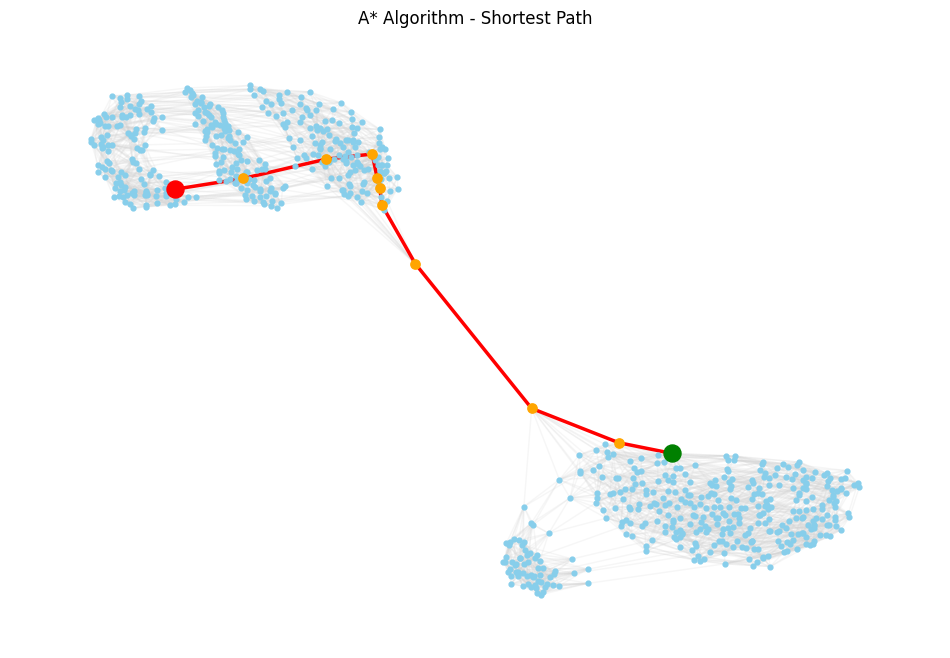

In [17]:
import matplotlib.pyplot as plt
import networkx as nx

# Set node positions
pos = nx.spring_layout(G, seed=42, iterations=30)

plt.figure(figsize=(12, 8))

# Draw the complete graph
nx.draw_networkx_edges(
    G, pos,
    edge_color="lightgray",
    alpha=0.2
)

nx.draw_networkx_nodes(
    G, pos,
    node_size=12,
    node_color="skyblue"
)

# Highlight the shortest path
path_edges = list(zip(path[:-1], path[1:]))

nx.draw_networkx_edges(
    G, pos,
    edgelist=path_edges,
    edge_color="red",
    width=2.5
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=[int(node) for node in path],
    node_color="orange",
    node_size=45
)

# Highlight source and destination
nx.draw_networkx_nodes(
    G, pos,
    nodelist=[source],
    node_color="green",
    node_size=150
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=[destination],
    node_color="red",
    node_size=150
)

plt.title("A* Algorithm - Shortest Path")
plt.axis("off")
plt.show()